# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : A Bintang Aril S
- NIM   : 241011401317
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [5]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 17   # isi dengan 2 digit terakhir NIM Anda

In [6]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = X.shape[0]
    shuffled_indices = np.random.permutation(n_samples)
    
    test_size = int(n_samples * test_size)
    test_indices = shuffled_indices[:test_size]
    train_indices = shuffled_indices[test_size:]
    
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris dan kolom: (40, 2)


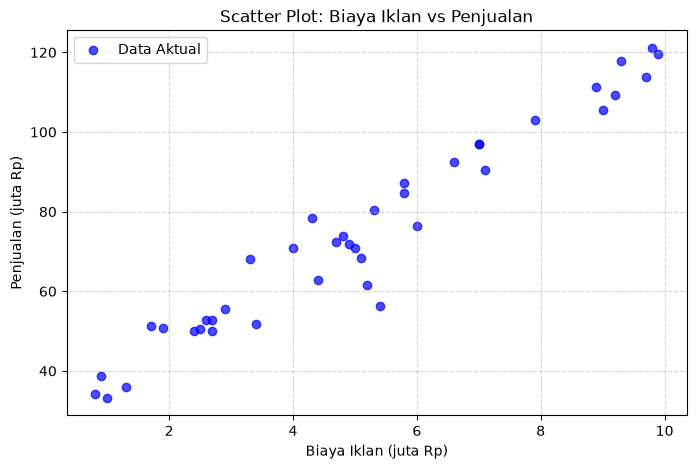

In [7]:
# A1: Load & Visualisasi Data
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data:")
display(df_ads.head())
print(f"Jumlah baris dan kolom: {df_ads.shape}")

# Pisahkan X dan y (pastikan X berdimensi 2: (n, 1))
X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

# Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, label='Data Aktual')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [8]:
# A2: Split Data
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Shape X_train: {X_train_ads.shape}")
print(f"Shape X_test : {X_test_ads.shape}")
print(f"Shape y_train: {y_train_ads.shape}")
print(f"Shape y_test : {y_test_ads.shape}")

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [9]:
# A3: Training Linear Regression (Normal Equation)
class LinearRegressionNormal:
    def fit(self, X, y):
        # Tambahkan kolom bias (intercept) yang berisi nilai 1
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        # Normal Equation: theta = (X^T * X)^(-1) * X^T * y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        
    def predict(self, X):
        return X.dot(self.coef_) + self.intercept_

model_lr = LinearRegressionNormal()
model_lr.fit(X_train_ads, y_train_ads)

b = model_lr.intercept_
m = model_lr.coef_[0]

print(f"Intercept (b): {b:.4f}")
print(f"Koefisien (m): {m:.4f}")
print(f"Persamaan Garis Regresi: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b): 28.0205
Koefisien (m): 9.2186
Persamaan Garis Regresi: y_hat = 28.0205 + 9.2186 * X


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [10]:
# A4: Implementasi metrik evaluasi regresi manual
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Prediksi train & test
y_train_pred = model_lr.predict(X_train_ads)
y_test_pred = model_lr.predict(X_test_ads)

# Hitung metrik
eval_results = {
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Training": [
        mean_absolute_error(y_train_ads, y_train_pred),
        mean_squared_error(y_train_ads, y_train_pred),
        root_mean_squared_error(y_train_ads, y_train_pred),
        r2_score(y_train_ads, y_train_pred)
    ],
    "Testing": [
        mean_absolute_error(y_test_ads, y_test_pred),
        mean_squared_error(y_test_ads, y_test_pred),
        root_mean_squared_error(y_test_ads, y_test_pred),
        r2_score(y_test_ads, y_test_pred)
    ]
}

df_eval = pd.DataFrame(eval_results)
display(df_eval)

,Metric,Training,Testing
0,MAE,4.559696,3.941851
1,MSE,40.231685,20.215210
2,RMSE,6.342845,4.496133
3,R² Score,0.940124,0.944720


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR: 0.001 -> Intercept: 20.2805, Koefisien: 10.4538
LR: 0.02 -> Intercept: 28.0205, Koefisien: 9.2186


c:\Users\A.HUSNI KML\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\A.HUSNI KML\AppData\Local\Temp\ipykernel_18496\2468190052.py:25: RuntimeWarning: overflow encountered in square
  cost = np.mean((y_predicted - y) ** 2)
C:\Users\A.HUSNI KML\AppData\Local\Temp\ipykernel_18496\2468190052.py:17: RuntimeWarning: overflow encountered in dot
  dw = (1 / n_samples) * X.T.dot(y_predicted - y)
C:\Users\A.HUSNI KML\AppData\Local\Temp\ipykernel_18496\2468190052.py:21: RuntimeWarning: invalid value encountered in subtract
  self.m -= self.lr * dw
c:\Users\A.HUSNI KML\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


LR: 0.1 -> Intercept: nan, Koefisien: nan


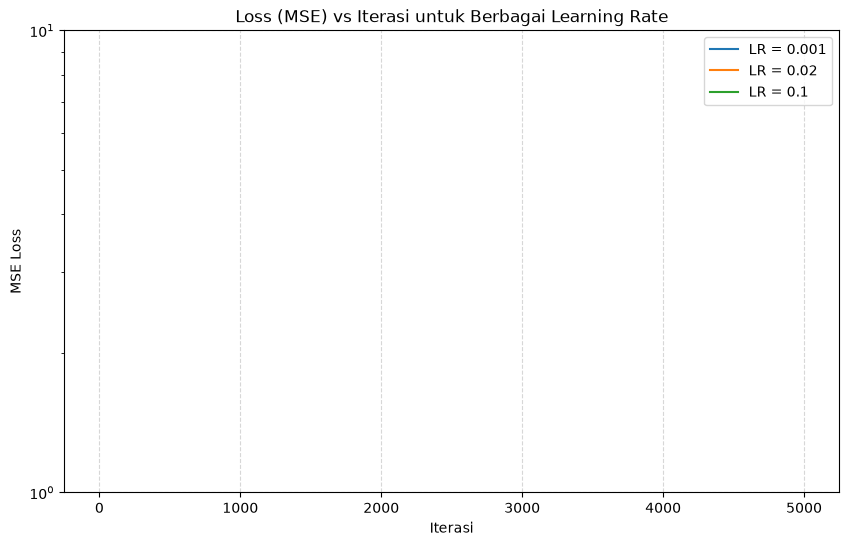

In [11]:
# A5: Linear Regression dengan Gradient Descent (LinearRegressionGD dari materi)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.cost_history = []
        
    def fit(self, X, y):
        n_samples = X.shape[0]
        self.b = 0.0
        self.m = np.zeros(X.shape[1])
        
        for _ in range(self.n_iterations):
            y_predicted = X.dot(self.m) + self.b
            
            # Hitunggradien
            dw = (1 / n_samples) * X.T.dot(y_predicted - y)
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            # Update parameter
            self.m -= self.lr * dw
            self.b -= self.lr * db
            
            # Simpan MSE loss
            cost = np.mean((y_predicted - y) ** 2)
            self.cost_history.append(cost)
            
    def predict(self, X):
        return X.dot(self.m) + self.b

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

plt.figure(figsize=(10, 6))
for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train_ads, y_train_ads)
    gd_models[lr] = gd
    print(f"LR: {lr} -> Intercept: {gd.b:.4f}, Koefisien: {gd.m[0]:.4f}")
    plt.plot(gd.cost_history, label=f'LR = {lr}')

plt.title('Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('MSE Loss')
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

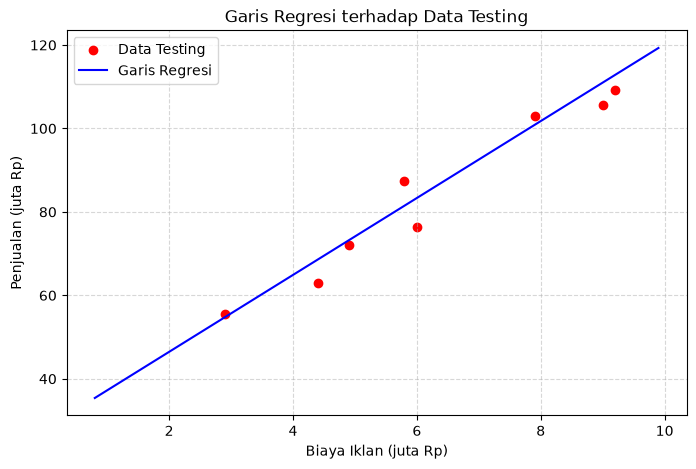

Biaya Iklan: 4.5 juta Rp -> Estimasi Penjualan: 69.5040 juta Rp
Biaya Iklan: 7.0 juta Rp -> Estimasi Penjualan: 92.5505 juta Rp
Biaya Iklan: 12.0 juta Rp -> Estimasi Penjualan: 138.6433 juta Rp


In [12]:
# A6: Visualisasi Garis Regresi pada Data Testing & Prediksi Nilai Baru
plt.figure(figsize=(8, 5))
plt.scatter(X_test_ads, y_test_ads, color='red', label='Data Testing')
X_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_line = model_lr.predict(X_line)
plt.plot(X_line, y_line, color='blue', label='Garis Regresi')
plt.title('Garis Regresi terhadap Data Testing')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Prediksi biaya iklan 4.5, 7, dan 12 juta
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = model_lr.predict(biaya_baru)

for biaya, pred in zip(biaya_baru.flatten(), prediksi_penjualan):
    print(f"Biaya Iklan: {biaya} juta Rp -> Estimasi Penjualan: {pred:.4f} juta Rp")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Distribusi Label Spam:
Spam
0    35
1    25
Name: count, dtype: int64


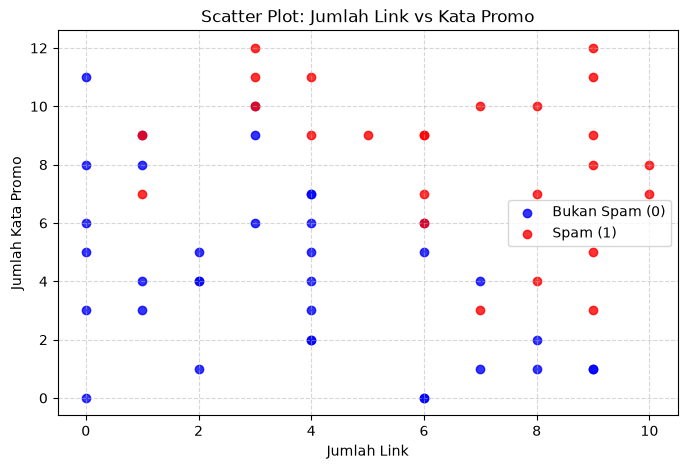

In [13]:
# B1: Load & Visualisasi Email_Data.csv
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data:")
display(df_email.head())

# Hitung jumlah email Spam dan Bukan Spam
print("\nDistribusi Label Spam:")
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='blue', label='Bukan Spam (0)', alpha=0.8)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='red', label='Spam (1)', alpha=0.8)
plt.title('Scatter Plot: Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -14.6591
Koefisien (m1, m2): [1.42230558 1.07629573]
Persamaan: P(Spam) = sigmoid(-14.6591 + 1.4223*Link + 1.0763*KataPromo)


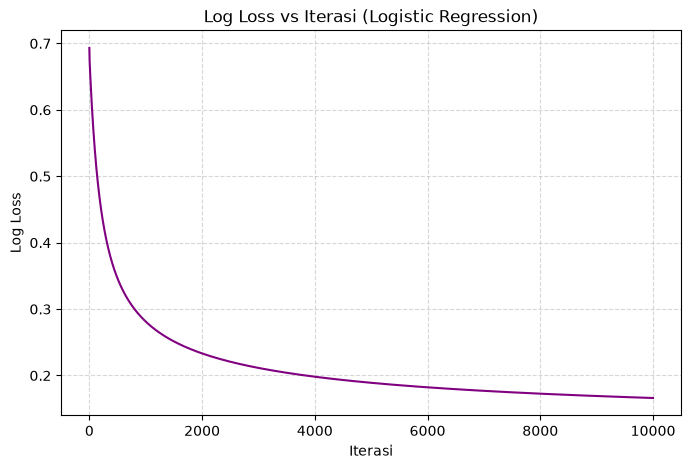

In [14]:
# B2: Split Data & Logistic Regression Training
X_train_em, X_test_em, y_train_em, y_test_em = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.cost_history = []
        
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.b = 0.0
        self.m = np.zeros(n_features)
        
        for _ in range(self.n_iterations):
            linear_model = X.dot(self.m) + self.b
            y_predicted = self.sigmoid(linear_model)
            
            # Gradien
            dw = (1 / n_samples) * X.T.dot(y_predicted - y)
            db = (1 / n_samples) * np.sum(y_predicted - y)
            
            self.m -= self.lr * dw
            self.b -= self.lr * db
            
            # Log Loss
            epsilon = 1e-15
            y_predicted = np.clip(y_predicted, epsilon, 1 - epsilon)
            cost = -np.mean(y * np.log(y_predicted) + (1 - y) * np.log(1 - y_predicted))
            self.cost_history.append(cost)
            
    def predict_proba(self, X):
        return self.sigmoid(X.dot(self.m) + self.b)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_logreg = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_logreg.fit(X_train_em, y_train_em)

print(f"Intercept (b): {model_logreg.b:.4f}")
print(f"Koefisien (m1, m2): {model_logreg.m}")
print(f"Persamaan: P(Spam) = sigmoid({model_logreg.b:.4f} + {model_logreg.m[0]:.4f}*Link + {model_logreg.m[1]:.4f}*KataPromo)")

# Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 5))
plt.plot(model_logreg.cost_history, color='purple')
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [15]:
# B3: Implementasi Metrik Evaluasi Klasifikasi Manual
def confusion_matrix(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]])

def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

y_test_pred_default = model_logreg.predict(X_test_em, threshold=0.5)

cm = confusion_matrix(y_test_em, y_test_pred_default)
acc = accuracy_score(y_test_em, y_test_pred_default)

TN, FP = cm[0, 0], cm[0, 1]
FN, TP = cm[1, 0], cm[1, 1]

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("Confusion Matrix (Threshold 0.5):")
print(cm)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Confusion Matrix (Threshold 0.5):
[[7 1]
 [2 5]]
Accuracy  : 0.8000
Precision : 0.8333
Recall    : 0.7143
F1-Score  : 0.7692


**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

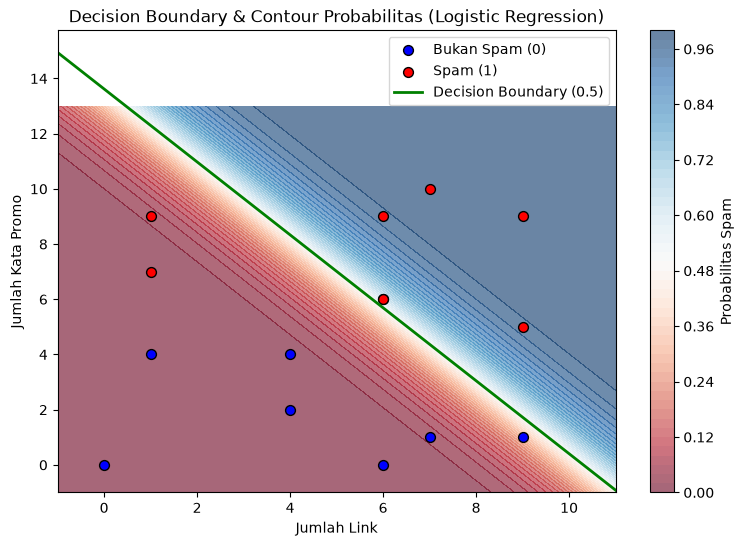

In [16]:
# B4: Visualisasi Decision Boundary
plt.figure(figsize=(9, 6))
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = model_logreg.predict_proba(grid_points).reshape(xx.shape)

plt.contourf(xx, yy, probs, levels=50, cmap='RdBu', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

# Plot data testing
plt.scatter(X_test_em[y_test_em == 0, 0], X_test_em[y_test_em == 0, 1], color='blue', edgecolor='k', label='Bukan Spam (0)', s=50)
plt.scatter(X_test_em[y_test_em == 1, 0], X_test_em[y_test_em == 1, 1], color='red', edgecolor='k', label='Spam (1)', s=50)

# Garis Decision Boundary (P = 0.5 -> b + m1*x1 + m2*x2 = 0)
x_db = np.linspace(x_min, x_max, 100)
y_db = -(model_logreg.b + model_logreg.m[0] * x_db) / model_logreg.m[1]
plt.plot(x_db, y_db, color='green', linewidth=2, label='Decision Boundary (0.5)')

plt.title('Decision Boundary & Contour Probabilitas (Logistic Regression)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.show()

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [17]:
# B5: Eksperimen Berbagai Threshold
thresholds = [0.3, 0.5, 0.7]
results_b5 = []

for th in thresholds:
    y_pred_th = model_logreg.predict(X_test_em, threshold=th)
    cm_th = confusion_matrix(y_test_em, y_pred_th)
    TN, FP = cm_th[0, 0], cm_th[0, 1]
    FN, TP = cm_th[1, 0], cm_th[1, 1]
    
    prec = TP / (TP + FP) if (TP + FP) > 0 else 0
    rec = TP / (TP + FN) if (TP + FN) > 0 else 0
    acc = (TP + TN) / np.sum(cm_th)
    
    results_b5.append({
        "Threshold": th,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "Confusion Matrix": str(cm_th.tolist())
    })

df_b5 = pd.DataFrame(results_b5)
display(df_b5)

,Threshold,Accuracy,Precision,Recall,Confusion Matrix
0,0.3,0.733333,0.714286,0.714286,"[[6, 2], [2, 5]]"
1,0.5,0.800000,0.833333,0.714286,"[[7, 1], [2, 5]]"
2,0.7,0.800000,1.000000,0.571429,"[[8, 0], [3, 4]]"


**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [18]:
# B6: Prediksi Email Baru (E1, E2, E3, E4)
email_baru = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

# Gunakan threshold pilihan (misal: 0.5)
chosen_threshold = 0.5
probs_baru = model_logreg.predict_proba(email_baru)
preds_baru = (probs_baru >= chosen_threshold).astype(int)

df_pred_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": email_baru[:, 0],
    "KataPromo": email_baru[:, 1],
    "Probabilitas Spam": probs_baru,
    "Prediksi Kelas": preds_baru,
    "Keterangan": ["Spam" if p == 1 else "Bukan Spam" for p in preds_baru]
})
display(df_pred_baru)

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Kelas,Keterangan
0,E1,1,2,0.000015,0,Bukan Spam
1,E2,5,6,0.251651,0,Bukan Spam
2,E3,9,10,0.999864,1,Spam
3,E4,2,11,0.506184,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic regression dinamakan "regression" karena berbasis pada model regresi linier yang menghitung kombinasi linear dari fitur masukan. Namun, algoritma ini menerapkan fungsi sigmoid di tahap akhirnya untuk memetakan nilai kontinu tersebut ke dalam rentang probabilitas antara 0 dan 1, sehingga dapat digunakan untuk tugas klasifikasi biner.

**Jawaban C2:** Normal equation menghitung parameter optimal secara langsung menggunakan invers matriks tanpa iterasi, namun menjadi sangat lambat jika ukuran dataset atau jumlah fiturnya sangat besar. Sebaliknya, gradient descent memperbarui bobot secara bertahap melalui iterasi, sehingga jauh lebih efisien dan wajib digunakan ketika dataset berukuran sangat besar.

**Jawaban C3:** Evaluasi wajib dilakukan pada data testing (data yang belum pernah dilihat model saat pelatihan) untuk mengukur kemampuan generalisasi model pada data dunia nyata. Overfitting adalah kondisi ketika model terlalu menghafal data training sehingga kinerjanya sangat baik di data latihan tetapi buruk saat diuji pada data baru.

**Jawaban C4:** Linear regression menggunakan MSE karena target keluarannya berupa nilai kontinu (numerik), di mana selisih kuadrat cocok untuk mengukur jarak galat. Sebaliknya, logistic regression menggunakan log loss karena keluarannya berupa probabilitas diskrit (0 atau 1), dan fungsi log loss memberikan penalti yang tinggi jika model salah memprediksi probabilitas dengan tingkat keyakinan yang tinggi.

**Jawaban C5:** Hasil angka bisa berbeda karena penggunaan fungsi train_test_split yang melibatkan pengacakan data berbasis random_state. Walaupun Anda menggunakan dataset yang sama, nilai 2 digit terakhir NIM yang berbeda membuat titik data yang masuk ke dalam kelompok training dan testing berbeda pada setiap komputer mahasiswa.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [19]:
# Jawaban Bonus: Perbandingan dengan Scikit-Learn
from sklearn.linear_model import LinearRegression, LogisticRegression as SkLogReg

# Linear Regression sklearn
sk_lr = LinearRegression()
sk_lr.fit(X_train_ads, y_train_ads)
print("--- Linear Regression ---")
print(f"Sklearn Intercept: {sk_lr.intercept_:.4f} | Manual Intercept: {model_lr.intercept_:.4f}")
print(f"Sklearn Coef     : {sk_lr.coef_[0]:.4f}   | Manual Coef     : {model_lr.coef_[0]:.4f}")

# Logistic Regression sklearn
# Catatan: sklearn secara default menggunakan L2 Regularization (penalty='l2', C=1.0)
sk_log = SkLogReg(penalty=None, solver='lbfgs') # Menonaktifkan penalty agar setara dengan manual
sk_log.fit(X_train_em, y_train_em)
print("\n--- Logistic Regression ---")
print(f"Sklearn Intercept: {sk_log.intercept_[0]:.4f} | Manual Intercept: {model_logreg.b:.4f}")
print(f"Sklearn Coef     : {sk_log.coef_[0]}    | Manual Coef     : {model_logreg.m}")

--- Linear Regression ---
Sklearn Intercept: 28.0205 | Manual Intercept: 28.0205
Sklearn Coef     : 9.2186   | Manual Coef     : 9.2186

--- Logistic Regression ---
Sklearn Intercept: -31.0729 | Manual Intercept: -14.6591
Sklearn Coef     : [3.10408239 2.21037246]    | Manual Coef     : [1.42230558 1.07629573]


c:\Users\A.HUSNI KML\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):** Hasil koefisien antara implementasi manual NumPy dan scikit-learn akan sangat mirip atau identik apabila parameter regularisasi dinonaktifkan (penalty=None). Jika menggunakan konfigurasi bawaan scikit-learn (yang mengaktifkan regularisasi L2 secara default), akan terdapat sedikit perbedaan nilai koefisien karena adanya penalti bobot untuk mencegah overfitting.